# Phase 4 — Exploratory Data Analysis

Understand AAPL closing prices, daily returns, and trading volume
before feature engineering and modeling.

Scope:
- Training period: 2010–2019.
- Validation and test periods excluded from EDA.
- Preserve the raw CSV.
- Investigate unusual observations before deciding whether to clean them.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import yaml

PROJECT_ROOT = Path.cwd().resolve()

# Notebook may start from the project root or notebooks folder.
if not (PROJECT_ROOT / "configs" / "base.yaml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "configs" / "base.yaml").exists():
    raise FileNotFoundError(
        "Open this notebook from the project root or notebooks folder."
    )

print("Project root:", PROJECT_ROOT)

Project root: /Users/manavkumar/Desktop/stock-price-lstm


In [2]:
with (PROJECT_ROOT / "configs" / "base.yaml").open(
    encoding="utf-8"
) as file:
    config = yaml.safe_load(file)

settings = config["data"]

ticker = settings["ticker"].strip().upper()
start = settings["start_date"]
end = settings["end_date_exclusive"]

input_path = (
    PROJECT_ROOT
    / settings["raw_dir"]
    / f"{ticker}_{start}_{end}_raw.csv"
)

raw = pd.read_csv(
    input_path,
    index_col="Date",
    parse_dates=["Date"],
)

if not isinstance(raw.index, pd.DatetimeIndex):
    raise ValueError("Dates were not parsed correctly.")

if raw.index.hasnans or raw.index.has_duplicates:
    raise ValueError("Invalid or duplicate dates. Revisit validation.")

if not raw.index.is_monotonic_increasing:
    raise ValueError("Dates are not in chronological order.")

train_end = pd.Timestamp(config["split"]["train_end"])

train = raw.loc[
    (raw.index >= pd.Timestamp(start))
    & (raw.index <= train_end)
].copy()

if len(train) < 2:
    raise ValueError("Not enough training observations.")

# Keep only the training table available for exploration.
del raw

figure_dir = PROJECT_ROOT / config["paths"]["figures"]
metrics_dir = PROJECT_ROOT / config["paths"]["metrics"]

figure_dir.mkdir(parents=True, exist_ok=True)
metrics_dir.mkdir(parents=True, exist_ok=True)

print("Ticker:", ticker)
print("Training shape:", train.shape)
print("First training date:", train.index.min().date())
print("Last training date:", train.index.max().date())

train.head()

Ticker: AAPL
Training shape: (2516, 6)
First training date: 2010-01-04
Last training date: 2019-12-31


,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2010-01-04,6.400961,7.643214,7.660714,7.585000,7.622500,493729600
2010-01-05,6.412027,7.656429,7.699643,7.616071,7.664286,601904800
2010-01-06,6.310034,7.534643,7.686786,7.526786,7.656429,552160000
2010-01-07,6.298368,7.520714,7.571429,7.466071,7.562500,477131200
2010-01-08,6.340244,7.570714,7.571429,7.466429,7.510714,447610800


In [3]:
summary = train.describe().T

summary.to_csv(
    metrics_dir / f"{ticker}_train_summary.csv"
)

summary.round(3)

,count,mean,std,min,25%,50%,75%,max
Adj Close,2516.0,2.504000e+01,1.386400e+01,5.744000e+00,1.374400e+01,2.217600e+01,3.508800e+01,7.065900e+01
Close,2516.0,2.758600e+01,1.404300e+01,6.859000e+00,1.617900e+01,2.487000e+01,3.763800e+01,7.341200e+01
High,2516.0,2.782500e+01,1.414500e+01,7.000000e+00,1.634600e+01,2.506900e+01,3.798500e+01,7.349300e+01
Low,2516.0,2.733000e+01,1.392000e+01,6.795000e+00,1.604900e+01,2.459600e+01,3.729200e+01,7.238000e+01
Open,2516.0,2.758000e+01,1.402200e+01,6.870000e+00,1.624600e+01,2.479100e+01,3.758100e+01,7.278000e+01
Volume,2516.0,2.995931e+08,2.352800e+08,4.544800e+07,1.247008e+08,2.218420e+08,4.067637e+08,1.880998e+09


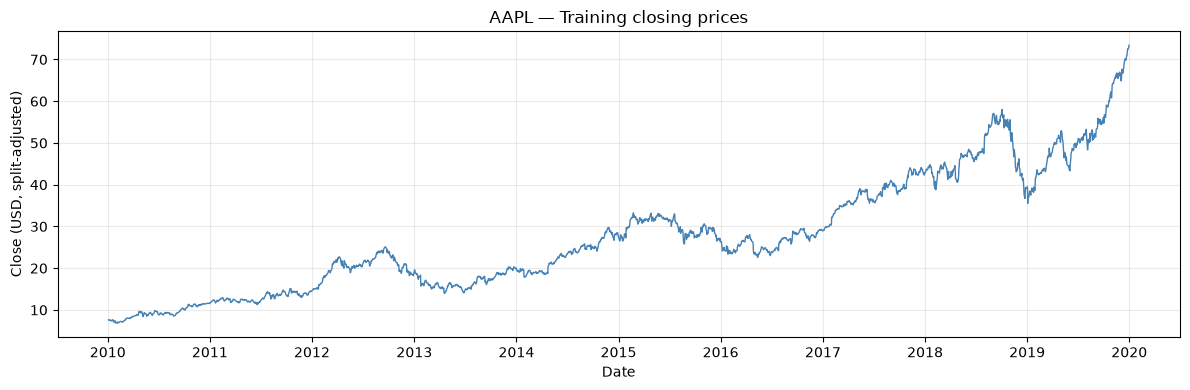

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    train.index,
    train["Close"],
    color="steelblue",
    linewidth=1,
)

ax.set_title(f"{ticker} — Training closing prices")
ax.set_xlabel("Date")
ax.set_ylabel("Close (USD, split-adjusted)")
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    figure_dir / f"{ticker}_train_close.png",
    dpi=150,
)
plt.show()

# Daily price returns

A return measures the relative change from the previous session:

return = (current Close / previous Close) - 1

Example:
- Previous Close = 100
- Current Close = 103
- Return = 0.03 = 3%

These are Close-based price returns, not dividend-inclusive total returns.

In [5]:
daily_return = train["Close"].pct_change(fill_method=None)
return_pct = daily_return * 100

return_table = pd.DataFrame({
    "Previous Close": train["Close"].shift(1),
    "Close": train["Close"],
    "Daily Return (%)": return_pct,
})

return_table.head()

,Previous Close,Close,Daily Return (%)
Date,,,
2010-01-04,NaN,7.643214,NaN
2010-01-05,7.643214,7.656429,0.172893
2010-01-06,7.656429,7.534643,-1.590632
2010-01-07,7.534643,7.520714,-0.184871
2010-01-08,7.520714,7.570714,0.664833


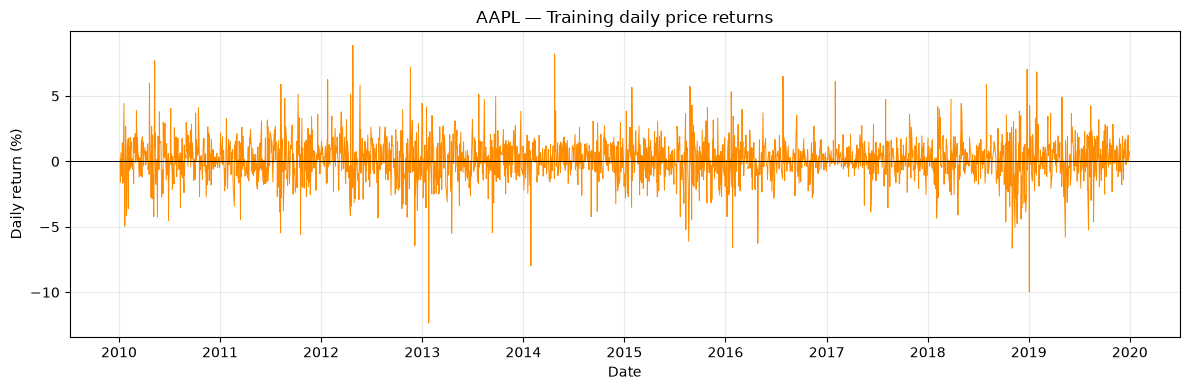

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    train.index,
    return_pct,
    color="darkorange",
    linewidth=0.7,
)
ax.axhline(0, color="black", linewidth=0.7)

ax.set_title(f"{ticker} — Training daily price returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily return (%)")
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    figure_dir / f"{ticker}_train_returns.png",
    dpi=150,
)
plt.show()

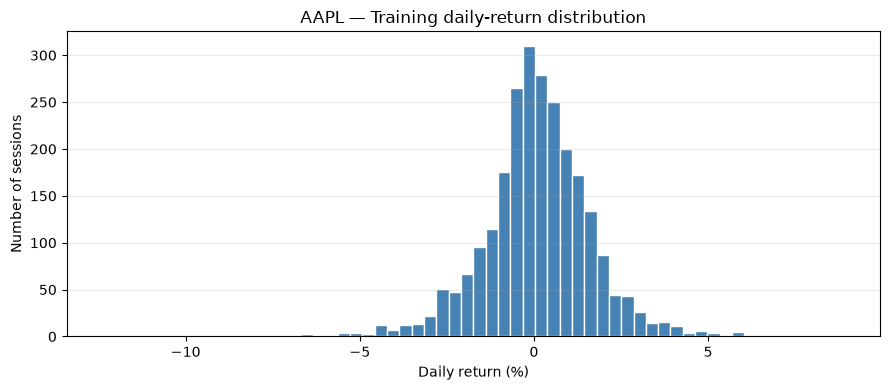

count    2515.000000
mean        0.103187
std         1.623339
min       -12.355785
1%         -4.310702
5%         -2.500110
50%         0.089329
95%         2.613156
99%         4.430009
max         8.874128
Name: Daily Return (%), dtype: float64

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.hist(
    return_pct.dropna(),
    bins=60,
    color="steelblue",
    edgecolor="white",
)

ax.set_title(f"{ticker} — Training daily-return distribution")
ax.set_xlabel("Daily return (%)")
ax.set_ylabel("Number of sessions")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    figure_dir / f"{ticker}_train_return_distribution.png",
    dpi=150,
)
plt.show()

return_summary = return_pct.describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
).rename("Daily Return (%)")

return_summary.to_csv(
    metrics_dir / f"{ticker}_train_return_summary.csv"
)

return_summary

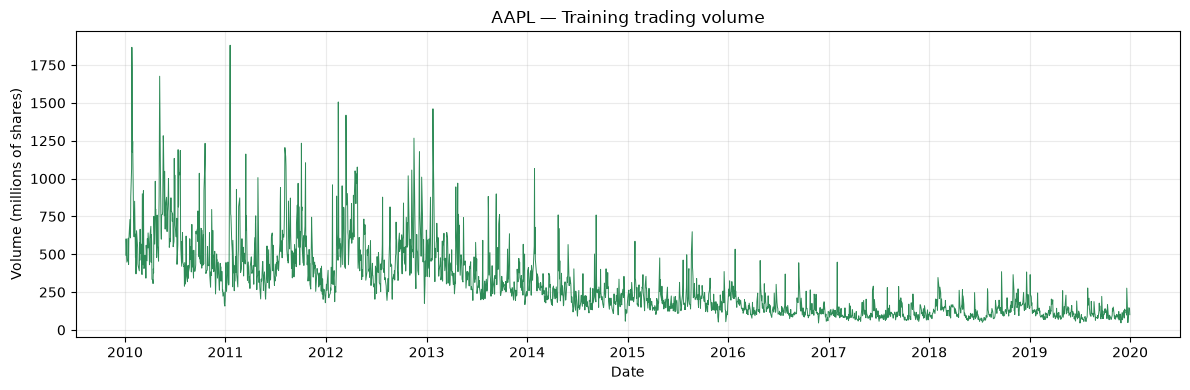

In [8]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    train.index,
    train["Volume"] / 1_000_000,
    color="seagreen",
    linewidth=0.7,
)

ax.set_title(f"{ticker} — Training trading volume")
ax.set_xlabel("Date")
ax.set_ylabel("Volume (millions of shares)")
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    figure_dir / f"{ticker}_train_volume.png",
    dpi=150,
)
plt.show()

In [9]:
largest_dates = daily_return.abs().nlargest(10).index

largest_moves = return_table.loc[largest_dates].copy()
largest_moves["Volume"] = train.loc[largest_dates, "Volume"]

largest_moves.to_csv(
    metrics_dir / f"{ticker}_train_largest_moves.csv",
    index_label="Date",
)

largest_moves.round(4)

,Previous Close,Close,Daily Return (%),Volume
Date,,,,
2013-01-24,18.3575,16.0893,-12.3558,1460852400
2019-01-03,39.4800,35.5475,-9.9607,365248800
2012-04-25,20.0100,21.7857,8.8741,905777600
2014-04-24,18.7411,20.2775,8.1982,759911600
2014-01-28,19.6607,18.0893,-7.9927,1065523200
2010-05-10,8.4236,9.0711,7.6868,984306400
2012-11-19,18.8457,20.2046,7.2108,823317600
2018-12-26,36.7075,39.2925,7.0422,234330000
2019-01-30,38.6700,41.3125,6.8335,244439200


## EDA observations

1. Closing-price behaviour:
   - ...

2. Periods with larger daily movements:
   - ...

3. Shape and extremes of the return distribution:
   - ...

4. Trading-volume behaviour:
   - ...

5. Unusual observations needing investigation:
   - ...

## Modeling implications

- Price levels vary over time; scaling will be fitted on training data only.
- Extreme returns will not be removed without supporting evidence.
- Visible patterns do not establish predictive performance.
- Feature usefulness will be assessed through validation experiments.

## EDA observations

- Training data contains 2,516 sessions from 2010-01-04 to
  2019-12-31.
- There are 2,515 daily returns; the first return is undefined.
- Closing prices show long-term growth with substantial declines.
- Daily returns are concentrated near zero, with occasional
  extreme movements and apparent volatility clustering.
- Mean daily price return is approximately 0.1032%.
- Daily-return standard deviation is approximately
  1.6233 percentage points.
- Approximately 90% of daily returns lie between -2.50% and +2.61%.
- The largest observed decline is -12.36%; the largest increase
  is +8.87%.
- Reported trading volume generally declines over the period
  and includes large spikes.

## Modeling implications

- Fit scaling only on training observations.
- Explore returns, rolling volatility, and relative volume
  as candidate features.
- Retain extreme observations unless evidence establishes errors.
- Evaluate feature usefulness on validation data.
- Keep the final test period out of exploratory decisions.